# Εργασία 5 – Δέντρα Απόφασης & Τυχαία Δάση

Σε αυτή την εργασία προβλέπω αν ένα δείγμα νερού είναι πόσιμο (Potability = 1) ή μη πόσιμο (Potability = 0), με βάση χημικές μετρήσεις. Αρχικά εξετάζω τα δεδομένα, μετά εκπαιδεύω Δέντρα Απόφασης με διάφορες υπερπαραμέτρους και τέλος αναλύω τους κανόνες, τη σημαντικότητα των χαρακτηριστικών και την καταλληλότερη μετρική.

# Import Libraries

In [1]:
from itertools import product
from pathlib import Path
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    fbeta_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text

seed = 0
pd.set_option('display.max_rows', 200)
pd.set_option('display.width', 250)

# Load Dataset

Το water_potability.csv είναι από το [Water Quality dataset](https://www.kaggle.com/datasets/adityakadiwal/water-potability) του Kaggle. Αν το αρχείο δεν υπάρχει στο Colab, κατεβαίνει αυτόματα από δημόσιο αντίγραφο του ίδιου dataset.

In [2]:
data_path = Path('water_potability.csv')
data_url = 'https://raw.githubusercontent.com/MainakRepositor/Datasets/master/water_potability.csv'

if not data_path.exists():
    urllib.request.urlretrieve(data_url, data_path)

df = pd.read_csv(data_path)
print('Διαστάσεις:', df.shape)
df.head()

Διαστάσεις: (3276, 10)


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


Το dataset έχει 3.276 δείγματα νερού και 9 χημικά χαρακτηριστικά: ph, Hardness (σκληρότητα), Solids (διαλυμένα στερεά), Chloramines (χλωραμίνες), Sulfate (θειικά), Conductivity (αγωγιμότητα), Organic_carbon (οργανικός άνθρακας), Trihalomethanes και Turbidity (θολότητα). Το target είναι η στήλη Potability.

# 1. Εξερεύνηση των δεδομένων

## Ιστογράμματα των χαρακτηριστικών

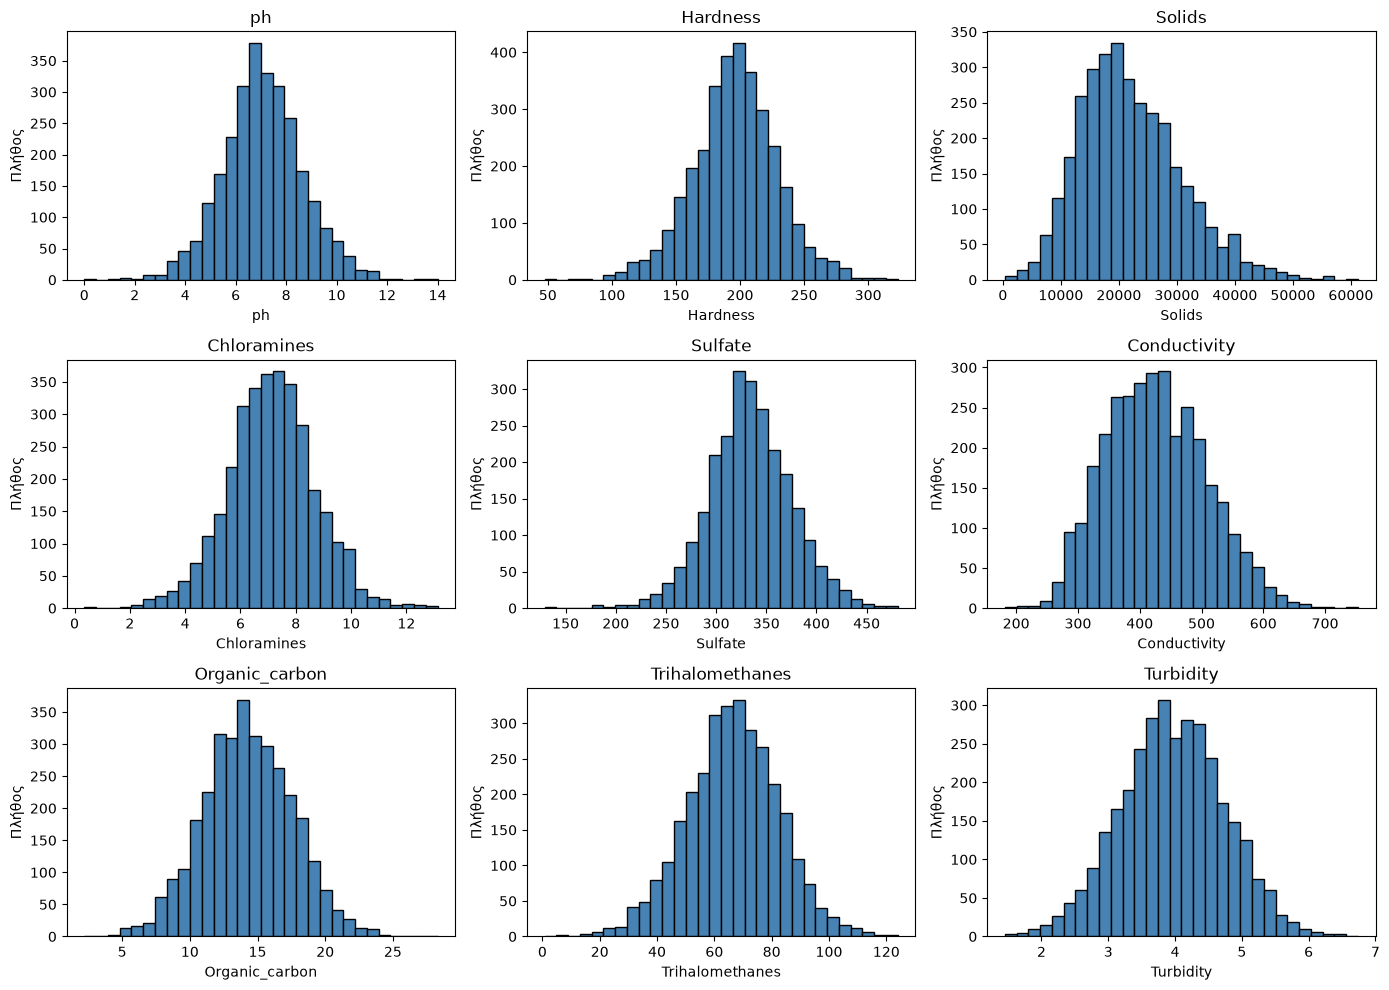

In [3]:
features = [c for c in df.columns if c != 'Potability']

fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.ravel(), features):
    ax.hist(df[col].dropna(), bins=30, color='steelblue', edgecolor='black')
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel('Πλήθος')

plt.tight_layout()
plt.show()

## Ραβδόγραμμα του target και ποσοστά κλάσεων

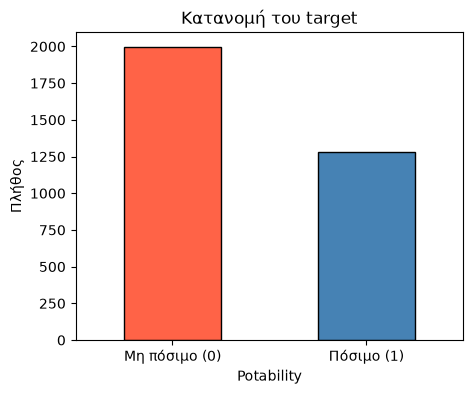

,Πλήθος,Ποσοστό %
Μη πόσιμο (0),1998,60.99
Πόσιμο (1),1278,39.01


In [4]:
target_counts = df['Potability'].value_counts().sort_index()

plt.figure(figsize=(5, 4))
target_counts.plot(kind='bar', color=['tomato', 'steelblue'], edgecolor='black')
plt.xticks([0, 1], ['Μη πόσιμο (0)', 'Πόσιμο (1)'], rotation=0)
plt.xlabel('Potability')
plt.ylabel('Πλήθος')
plt.title('Κατανομή του target')
plt.show()

class_table = pd.DataFrame({
    'Πλήθος': target_counts,
    'Ποσοστό %': (df['Potability'].value_counts(normalize=True).sort_index() * 100).round(2),
})
class_table.index = ['Μη πόσιμο (0)', 'Πόσιμο (1)']
class_table

## Ελλιπείς τιμές

In [5]:
missing = pd.DataFrame({
    'Ελλιπείς τιμές': df.isna().sum(),
    'Ποσοστό %': (df.isna().mean() * 100).round(2),
})
missing

,Ελλιπείς τιμές,Ποσοστό %
ph,491,14.99
Hardness,0,0.00
Solids,0,0.00
Chloramines,0,0.00
Sulfate,781,23.84
Conductivity,0,0.00
Organic_carbon,0,0.00
Trihalomethanes,162,4.95
Turbidity,0,0.00
Potability,0,0.00



**Παρατηρήσεις:** Όλα τα χαρακτηριστικά έχουν περίπου κανονική κατανομή (καμπάνα). Μόνο τα Solids έχουν ελαφριά ασυμμετρία προς τα δεξιά. Ελλιπείς τιμές έχουν τρεις στήλες: το pH (491, δηλαδή 14,99%), τα Sulfate (781, δηλαδή 23,84%) και τα Trihalomethanes (162, δηλαδή 4,95%). Οι υπόλοιπες στήλες είναι πλήρεις.

**Κατανομή του target:** Από τα 3.276 δείγματα, τα 1.998 (60,99%) είναι μη πόσιμα και τα 1.278 (39,01%) πόσιμα. Το dataset δεν είναι ισορροπημένο. Ένα μοντέλο που θα έλεγε πάντα «μη πόσιμο» θα είχε ήδη accuracy περίπου 61%, και αυτό είναι το όριο με το οποίο πρέπει να συγκρίνω τα δέντρα παρακάτω.


# 2. Το pH και το όριο του ΠΟΥ

Χωρίζω τα δείγματα σε τρεις ομάδες: pH < 6.5, 6.5 ≤ pH ≤ 8.5 και pH > 8.5. Τα δείγματα χωρίς τιμή pH δεν μπαίνουν σε καμία ομάδα.

,Μη πόσιμο,Πόσιμο,Σύνολο,Μη πόσιμο %,Πόσιμο %
Ομάδα pH,,,,,
pH < 6.5,612,356,968,63.2,36.8
6.5 ≤ pH ≤ 8.5,745,583,1328,56.1,43.9
pH > 8.5,327,162,489,66.9,33.1


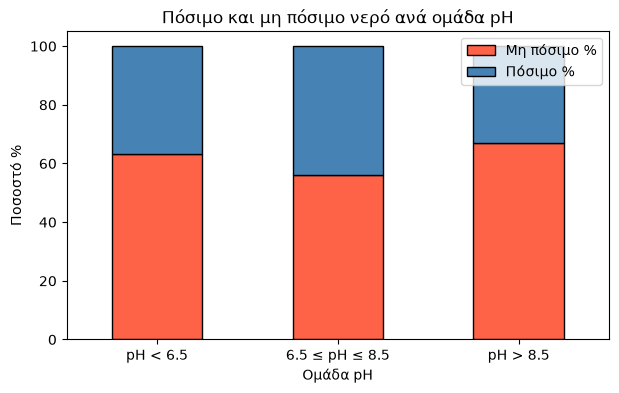

In [6]:
ph_known = df.dropna(subset=['ph']).copy()
labels = ['pH < 6.5', '6.5 ≤ pH ≤ 8.5', 'pH > 8.5']
ph_known['Ομάδα pH'] = pd.Categorical(
    np.select([ph_known['ph'] < 6.5, ph_known['ph'] <= 8.5], labels[:2], default=labels[2]),
    categories=labels,
    ordered=True,
)

ph_counts = pd.crosstab(ph_known['Ομάδα pH'], ph_known['Potability'])
ph_counts.columns = ['Μη πόσιμο', 'Πόσιμο']
ph_counts['Σύνολο'] = ph_counts.sum(axis=1)

ph_pct = pd.crosstab(ph_known['Ομάδα pH'], ph_known['Potability'], normalize='index') * 100
ph_pct.columns = ['Μη πόσιμο %', 'Πόσιμο %']

ph_table = pd.concat([ph_counts, ph_pct.round(1)], axis=1)
display(ph_table)

ph_table[['Μη πόσιμο %', 'Πόσιμο %']].plot(
    kind='bar', stacked=True, color=['tomato', 'steelblue'], edgecolor='black', figsize=(7, 4)
)
plt.xticks(rotation=0)
plt.ylabel('Ποσοστό %')
plt.title('Πόσιμο και μη πόσιμο νερό ανά ομάδα pH')
plt.show()


**Ερώτηση: Σε τι βαθμό επαληθεύεται η ιδιότητα αυτή στα δεδομένα;**

**Απάντηση:** Μόνο ασθενώς. Στην ομάδα 6.5 ≤ pH ≤ 8.5 το πόσιμο νερό είναι 43,9%, ενώ έξω από αυτήν είναι 36,8% (pH < 6.5) και 33,1% (pH > 8.5). Άρα η τάση είναι η σωστή, γιατί οι τιμές μέσα στο εύρος του ΠΟΥ έχουν περισσότερα πόσιμα δείγματα. Όμως η διαφορά είναι μικρή: ακόμη και μέσα στο προτεινόμενο εύρος το 56,1% του νερού είναι μη πόσιμο. Το pH μόνο του δεν αρκεί για να αποφασίσω αν το νερό είναι πόσιμο.


# 3. Διάγραμμα διασποράς pH – Chloramines

Τα πόσιμα δείγματα είναι μπλε και τα μη πόσιμα κόκκινα. Οι διακεκομμένες γραμμές δείχνουν τα όρια του ΠΟΥ (pH 6.5 και 8.5, χλωραμίνη 4 ppm).

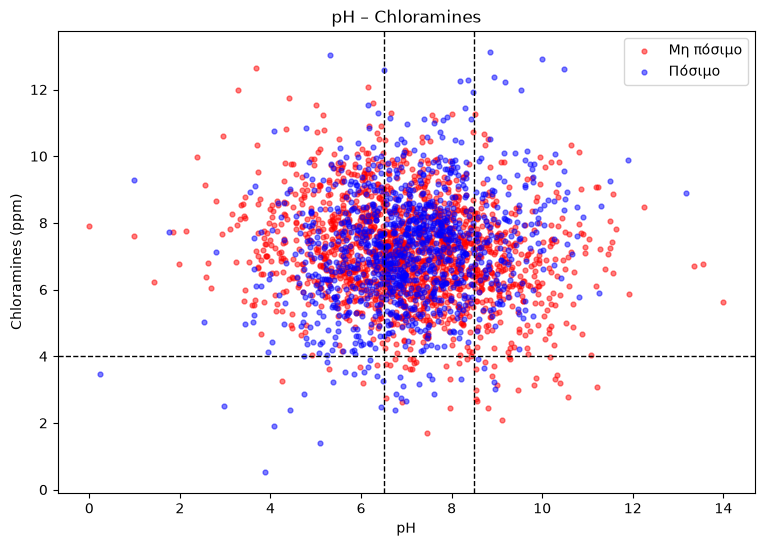

In [7]:
potable = df[df['Potability'] == 1]
not_potable = df[df['Potability'] == 0]

plt.figure(figsize=(9, 6))
plt.scatter(not_potable['ph'], not_potable['Chloramines'], c='red', s=12, alpha=0.5, label='Μη πόσιμο')
plt.scatter(potable['ph'], potable['Chloramines'], c='blue', s=12, alpha=0.5, label='Πόσιμο')

plt.axvline(6.5, color='black', linestyle='--', linewidth=1)
plt.axvline(8.5, color='black', linestyle='--', linewidth=1)
plt.axhline(4, color='black', linestyle='--', linewidth=1)

plt.xlabel('pH')
plt.ylabel('Chloramines (ppm)')
plt.title('pH – Chloramines')
plt.legend()
plt.show()

In [8]:
known = df.dropna(subset=['ph'])
inside = known[(known['ph'] >= 6.5) & (known['ph'] <= 8.5) & (known['Chloramines'] <= 4)]

print('Δείγματα με γνωστό pH:', len(known))
print('Δείγματα μέσα και στα δύο όρια του ΠΟΥ:', len(inside), f'({len(inside) / len(known) * 100:.1f}%)')
print(f'Ποσοστό πόσιμων μέσα στα όρια: {inside["Potability"].mean() * 100:.1f}%')
print(f'Ποσοστό πόσιμων στα υπόλοιπα δείγματα: {known.drop(inside.index)["Potability"].mean() * 100:.1f}%')
print(f'Δείγματα με Chloramines ≤ 4: {(df["Chloramines"] <= 4).sum()} από {len(df)} ({(df["Chloramines"] <= 4).mean() * 100:.1f}%)')

Δείγματα με γνωστό pH: 2785
Δείγματα μέσα και στα δύο όρια του ΠΟΥ: 30 (1.1%)
Ποσοστό πόσιμων μέσα στα όρια: 36.7%
Ποσοστό πόσιμων στα υπόλοιπα δείγματα: 39.6%
Δείγματα με Chloramines ≤ 4: 89 από 3276 (2.7%)



**Ερώτηση: Τι διαπιστώνετε για τη διαχωρισιμότητα των παραδειγμάτων;**

**Απάντηση:** Τα δύο χρώματα είναι πλήρως αναμεμειγμένα, άρα τα παραδείγματα δεν διαχωρίζονται με βάση αυτά τα δύο χαρακτηριστικά. Δεν μπορώ να φέρω ούτε ευθεία γραμμή ούτε ορθογώνιες περιοχές (όπως θα έκανε ένα δέντρο) που να ξεχωρίζουν τα μπλε από τα κόκκινα.

Επιπλέον, το όριο του ΠΟΥ για τη χλωραμίνη (4 ppm) σχεδόν δεν εμφανίζεται στα δεδομένα: μόνο 89 δείγματα (2,7%) το ικανοποιούν και μόνο 30 (1,1%) ικανοποιούν και τα δύο όρια (pH και χλωραμίνη). Το ποσοστό πόσιμου νερού μέσα στα όρια είναι 36,7% και έξω από αυτά 39,6%, δηλαδή ουσιαστικά ίδιο. Συμπεραίνω ότι τα όρια του ΠΟΥ δεν χρησιμοποιήθηκαν για να βγουν οι ετικέτες του dataset και ότι το πρόβλημα είναι δύσκολο.


# 4. Συμπλήρωση ελλιπών τιμών

Συμπληρώνω τις ελλιπείς τιμές με τη μέση τιμή της κάθε στήλης. Έτσι δεν χρησιμοποιώ σταθερά όπως 0 ή -1, που θα μπορούσε να μπερδευτεί με πραγματικές τιμές (το pH έχει πραγματικά και τιμή 0). Το βήμα είναι απαραίτητο, γιατί η scikit-learn δεν δέχεται ελλιπείς τιμές στα δέντρα.

In [9]:
df_filled = df.copy()
for col in ['ph', 'Sulfate', 'Trihalomethanes']:
    df_filled[col] = df_filled[col].fillna(df_filled[col].mean())

print('Ελλιπείς τιμές μετά τη συμπλήρωση:', df_filled.isna().sum().sum())

Ελλιπείς τιμές μετά τη συμπλήρωση: 0


Σημείωση: ακολουθώ τη σειρά της εκφώνησης (πρώτα συμπλήρωση, μετά διαχωρισμός). Έτσι οι μέσες τιμές υπολογίζονται και από δείγματα που θα καταλήξουν στο test set. Η επίδραση είναι μικρή, γιατί η μέση τιμή είναι μόνο ένας αριθμός ανά στήλη, αλλά αυστηρά θα έπρεπε να υπολογιστεί μόνο στο train set.

# 5. Numpy arrays και διαχωρισμός δεδομένων

In [10]:
x = df_filled[features].to_numpy()
y = df_filled['Potability'].to_numpy()

# πρώτα χωρίζω 10% για το test, μετά το 1/9 του υπολοίπου (10% του συνόλου) για το validation
x_trainval, x_test, y_trainval, y_test = train_test_split(
    x, y, test_size=0.10, random_state=seed, stratify=y
)
x_train, x_val, y_train, y_val = train_test_split(
    x_trainval, y_trainval, test_size=1 / 9, random_state=seed, stratify=y_trainval
)

print('x_train:', x_train.shape, '| y_train:', y_train.shape)
print('x_val:', x_val.shape, '| y_val:', y_val.shape)
print('x_test:', x_test.shape, '| y_test:', y_test.shape)

pd.DataFrame({
    'Train %': pd.Series(y_train).value_counts(normalize=True).sort_index() * 100,
    'Validation %': pd.Series(y_val).value_counts(normalize=True).sort_index() * 100,
    'Test %': pd.Series(y_test).value_counts(normalize=True).sort_index() * 100,
}).round(1)

x_train: (2620, 9) | y_train: (2620,)
x_val: (328, 9) | y_val: (328,)
x_test: (328, 9) | y_test: (328,)


,Train %,Validation %,Test %
0,61.0,61.0,61.0
1,39.0,39.0,39.0



Η εκφώνηση ζητά train–validation–test με ποσοστό «90–10». Το ερμήνευσα ως εξής: πρώτα κρατώ 10% του συνόλου για test και μετά αφαιρώ από το υπόλοιπο ένα ακόμη 10% του συνόλου για validation. Έτσι προκύπτει διαχωρισμός περίπου 80–10–10 (2.620 / 328 / 328 δείγματα). Όλοι οι διαχωρισμοί γίνονται με stratify και seed 0, και τα ποσοστά των κλάσεων μένουν ίδια (61% / 39%) σε όλα τα sets.


# 6. Δέντρο Απόφασης με προεπιλεγμένες παραμέτρους

In [11]:
tree = DecisionTreeClassifier(random_state=seed)
tree.fit(x_train, y_train)

pd.DataFrame({
    'Accuracy': [
        accuracy_score(y_train, tree.predict(x_train)),
        accuracy_score(y_val, tree.predict(x_val)),
        accuracy_score(y_test, tree.predict(x_test)),
    ]
}, index=['Train', 'Validation', 'Test']).round(4)

,Accuracy
Train,1.0000
Validation,0.6067
Test,0.5640


In [12]:
print('Βάθος δέντρου:', tree.get_depth())
print('Πλήθος φύλλων:', tree.get_n_leaves())
print('Μεγαλύτερη κλάση (μη πόσιμο) στο test set:', round((y_test == 0).mean(), 4))

Βάθος δέντρου: 34
Πλήθος φύλλων: 544
Μεγαλύτερη κλάση (μη πόσιμο) στο test set: 0.6098



**Ερώτηση: Πώς αποδίδει το δέντρο με τις προεπιλεγμένες παραμέτρους;**

**Απάντηση:** Το train accuracy είναι 100%, αλλά στο validation είναι 60,7% και στο test 56,4%. Το δέντρο μεγάλωσε χωρίς όριο (βάθος 34, 544 φύλλα) και απομνημόνευσε τα δεδομένα εκπαίδευσης, δηλαδή έχει overfitting. Το test accuracy είναι μάλιστα χαμηλότερο από το 61% που θα έπαιρνα αν έλεγα πάντα «μη πόσιμο».


# 7. Δοκιμή υπερπαραμέτρων

Δοκιμάζω όλους τους συνδυασμούς των υπερπαραμέτρων της εκφώνησης (2 × 3 × 2 × 2 × 2 × 2 = 96 συνδυασμοί). Για κάθε συνδυασμό:
- υπολογίζω την ακρίβεια με 5-fold cross-validation **μόνο στο train set** (στήλη CV Accuracy),
- εκπαιδεύω το δέντρο σε ολόκληρο το train set και μετρώ accuracy, precision και recall σε train και test.

Το precision και το recall αναφέρονται στην κλάση «πόσιμο» (Potability = 1). Όταν ένα δέντρο δεν προβλέπει καμία πόσιμη περίπτωση, το precision δεν ορίζεται και το βάζω 0.

In [13]:
param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [None, 3, 5],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'max_features': [None, 'sqrt'],
    'ccp_alpha': [0, 0.01],
}

rows = []
for criterion, max_depth, min_split, min_leaf, max_feat, alpha in product(*param_grid.values()):
    model = DecisionTreeClassifier(
        criterion=criterion,
        max_depth=max_depth,
        min_samples_split=min_split,
        min_samples_leaf=min_leaf,
        max_features=max_feat,
        ccp_alpha=alpha,
        random_state=seed,
    )
    cv_acc = cross_val_score(model, x_train, y_train, cv=5, scoring='accuracy').mean()

    model.fit(x_train, y_train)
    pred_train = model.predict(x_train)
    pred_test = model.predict(x_test)

    rows.append({
        'criterion': criterion,
        'max_depth': 'None' if max_depth is None else max_depth,
        'min_samples_split': min_split,
        'min_samples_leaf': min_leaf,
        'max_features': 'None' if max_feat is None else max_feat,
        'ccp_alpha': alpha,
        'CV Accuracy': cv_acc,
        'Train Accuracy': accuracy_score(y_train, pred_train),
        'Train Precision': precision_score(y_train, pred_train, zero_division=0),
        'Train Recall': recall_score(y_train, pred_train),
        'Test Accuracy': accuracy_score(y_test, pred_test),
        'Test Precision': precision_score(y_test, pred_test, zero_division=0),
        'Test Recall': recall_score(y_test, pred_test),
    })

results = pd.DataFrame(rows)
results.round(4)

,criterion,max_depth,min_samples_split,min_samples_leaf,max_features,ccp_alpha,CV Accuracy,Train Accuracy,Train Precision,Train Recall,Test Accuracy,Test Precision,Test Recall
0,gini,None,2,1,None,0.00,0.5790,1.0000,1.0000,1.0000,0.5640,0.4409,0.4375
1,gini,None,2,1,None,0.01,0.6099,0.6099,0.0000,0.0000,0.6098,0.0000,0.0000
2,gini,None,2,1,sqrt,0.00,0.5779,1.0000,1.0000,1.0000,0.5732,0.4545,0.4688
3,gini,None,2,1,sqrt,0.01,0.6099,0.6099,0.0000,0.0000,0.6098,0.0000,0.0000
4,gini,None,2,2,None,0.00,0.5920,0.9523,0.9817,0.8943,0.5915,0.4750,0.4453
5,gini,None,2,2,None,0.01,0.6099,0.6099,0.0000,0.0000,0.6098,0.0000,0.0000
6,gini,None,2,2,sqrt,0.00,0.5927,0.9359,0.9692,0.8630,0.5945,0.4779,0.4219
7,gini,None,2,2,sqrt,0.01,0.6099,0.6099,0.0000,0.0000,0.6098,0.0000,0.0000
8,gini,None,5,1,None,0.00,0.5779,0.9695,0.9738,0.9472,0.5671,0.4462,0.4531
9,gini,None,5,1,None,0.01,0.6099,0.6099,0.0000,0.0000,0.6098,0.0000,0.0000



**Παρατηρήσεις από τον πίνακα:**
- Με max_depth = None και ccp_alpha = 0 το δέντρο μεγαλώνει πολύ και το train accuracy είναι 92–100%, ενώ το test είναι μόνο 56–62%. Είναι το ίδιο overfitting με το ερώτημα 6.
- Με ccp_alpha = 0.01 το δέντρο κλαδεύεται τόσο πολύ που μένει ένας μόνο κόμβος: προβλέπει πάντα «μη πόσιμο». Το accuracy είναι 60,98%, αλλά precision και recall του πόσιμου νερού είναι 0. Η τιμή 0.01 είναι πολύ μεγάλη για αυτά τα δεδομένα.
- Η μείωση του βάθους (3 ή 5) μειώνει το overfitting (train accuracy 63–66%) και ανεβάζει το test accuracy. Μόνο 33 από τους 96 συνδυασμούς ξεπερνούν το 61% του «πάντα μη πόσιμο».
- Το cross-validation στο train set δίνει μέγιστο 63,0% (criterion = gini, max_depth = 5, min_samples_leaf = 2, χωρίς max_features), και μέγιστο test accuracy 62,8% έχουν δύο συνδυασμοί με entropy, max_depth = 5 και max_features = sqrt. Οι δύο καλύτεροι στο test έχουν ίδιο test accuracy (και πιθανότατα το ίδιο δέντρο).
- Οι διαφορές ανάμεσα στους καλούς συνδυασμούς είναι 1–2 δείγματα στο test set των 328 δειγμάτων (1 δείγμα = 0,3%), άρα δεν είναι αξιόπιστο να δώσω μεγάλη σημασία στη σειρά τους.


# 8. Καλύτερο δέντρο με max_depth = 5

Από τους συνδυασμούς με max_depth = 5 επιλέγω αυτόν με τη μεγαλύτερη ακρίβεια στο test, όπως ζητά η εκφώνηση. Αν υπάρχει ισοβαθμία, κρατώ αυτόν με την καλύτερη ακρίβεια στο cross-validation.

In [14]:
depth5 = results[results['max_depth'] == 5].sort_values(
    ['Test Accuracy', 'CV Accuracy'], ascending=False
)
display(depth5.head(6).round(4))

best5 = depth5.iloc[0]
params5 = {
    'criterion': best5['criterion'],
    'max_depth': 5,
    'min_samples_split': int(best5['min_samples_split']),
    'min_samples_leaf': int(best5['min_samples_leaf']),
    'max_features': None if best5['max_features'] == 'None' else best5['max_features'],
    'ccp_alpha': float(best5['ccp_alpha']),
}
print('Επιλεγμένος συνδυασμός:', params5)

,criterion,max_depth,min_samples_split,min_samples_leaf,max_features,ccp_alpha,CV Accuracy,Train Accuracy,Train Precision,Train Recall,Test Accuracy,Test Precision,Test Recall
94,entropy,5,5,2,sqrt,0.0,0.6229,0.6553,0.6142,0.3131,0.6280,0.5455,0.2812
82,entropy,5,2,1,sqrt,0.0,0.6225,0.6565,0.6169,0.3151,0.6280,0.5455,0.2812
86,entropy,5,2,2,sqrt,0.0,0.6229,0.6573,0.8563,0.1458,0.6220,0.6000,0.0938
90,entropy,5,5,1,sqrt,0.0,0.6202,0.6580,0.8621,0.1468,0.6220,0.6000,0.0938
38,gini,5,2,2,sqrt,0.0,0.6225,0.6603,0.8548,0.1556,0.6189,0.5714,0.0938
42,gini,5,5,1,sqrt,0.0,0.6187,0.6611,0.8602,0.1566,0.6189,0.5714,0.0938


Επιλεγμένος συνδυασμός: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'ccp_alpha': 0.0}


In [15]:
tree5 = DecisionTreeClassifier(random_state=seed, **params5)
tree5.fit(x_train, y_train)

print('Train accuracy:', round(tree5.score(x_train, y_train), 4))
print('Test accuracy:', round(tree5.score(x_test, y_test), 4))
print('Βάθος:', tree5.get_depth(), '| Φύλλα:', tree5.get_n_leaves())

Train accuracy: 0.6553
Test accuracy: 0.628
Βάθος: 5 | Φύλλα: 24


Για την απεικόνιση χρησιμοποιώ τη βιβλιοθήκη [dtreeviz](https://github.com/parrt/dtreeviz). Στο Colab χρειάζεται πρώτα εγκατάσταση.

In [ ]:
!pip install -q dtreeviz

In [ ]:
import dtreeviz

viz_model = dtreeviz.model(
    tree5,
    x_train,
    y_train,
    feature_names=features,
    target_name='Potability',
    class_names=['Not potable', 'Potable'],
)
viz_model.view(fontname='DejaVu Sans')

Για να διαβάζονται εύκολα οι κανόνες, τυπώνω το ίδιο δέντρο και σε μορφή κειμένου.

In [18]:
print(export_text(tree5, feature_names=features, class_names=['Μη πόσιμο', 'Πόσιμο'], show_weights=True))

|--- Sulfate <= 263.13
|   |--- Solids <= 27008.18
|   |   |--- Turbidity <= 4.60
|   |   |   |--- Chloramines <= 6.78
|   |   |   |   |--- Organic_carbon <= 17.99
|   |   |   |   |   |--- weights: [3.00, 7.00] class: Πόσιμο
|   |   |   |   |--- Organic_carbon >  17.99
|   |   |   |   |   |--- weights: [2.00, 0.00] class: Μη πόσιμο
|   |   |   |--- Chloramines >  6.78
|   |   |   |   |--- Conductivity <= 418.31
|   |   |   |   |   |--- weights: [8.00, 0.00] class: Μη πόσιμο
|   |   |   |   |--- Conductivity >  418.31
|   |   |   |   |   |--- weights: [4.00, 2.00] class: Μη πόσιμο
|   |   |--- Turbidity >  4.60
|   |   |   |--- Solids <= 24509.31
|   |   |   |   |--- weights: [0.00, 6.00] class: Πόσιμο
|   |   |   |--- Solids >  24509.31
|   |   |   |   |--- weights: [2.00, 1.00] class: Μη πόσιμο
|   |--- Solids >  27008.18
|   |   |--- Turbidity <= 4.67
|   |   |   |--- Hardness <= 190.92
|   |   |   |   |--- weights: [0.00, 18.00] class: Πόσιμο
|   |   |   |--- Hardness >  190.92
|   


**Επιλογή:** criterion = entropy, max_depth = 5, min_samples_split = 5, min_samples_leaf = 2, max_features = sqrt, ccp_alpha = 0 (test accuracy 62,8%). Η εκφώνηση ζητά επιλογή με βάση το test accuracy. Αυτό σημαίνει ότι το test set χρησιμοποιήθηκε για την επιλογή, οπότε το 62,8% είναι λίγο αισιόδοξο. Με βάση μόνο το cross-validation θα είχα διαλέξει άλλο συνδυασμό (gini, χωρίς max_features), που δίνει 61,6% στο test.

**Οι κανόνες του δέντρου (από το δέντρο και την έξοδο του export_text):**
- Η ρίζα χωρίζει με βάση τα **Sulfate** στο 263,13. Αριστερά (Sulfate ≤ 263,13) πηγαίνουν μόλις 89 από τα 2.620 δείγματα του train. Εκεί το δέντρο βγάζει «πόσιμο» όταν τα Solids είναι > 27.008, η θολότητα ≤ 4,67 και η σκληρότητα ≤ 190,92 (18 πόσιμα, 0 μη πόσιμα), καθώς και όταν η σκληρότητα είναι > 190,92 και ο οργανικός άνθρακας ≤ 17,07 (24 πόσιμα, 3 μη πόσιμα). Βγάζει επίσης «πόσιμο» όταν τα Solids είναι ≤ 27.008, η θολότητα > 4,60 και τα Solids ≤ 24.509 (6 πόσιμα, 0 μη πόσιμα).
- Δεξιά (Sulfate > 263,13), δηλαδή για τα περισσότερα δείγματα, τα επόμενα κριτήρια είναι η **σκληρότητα** (162,26) και το **pH** (8,21). Το μεγαλύτερο φύλλο (pH ≤ 8,21 και σκληρότητα ≤ 207,38) έχει 691 μη πόσιμα και 373 πόσιμα δείγματα, άρα προβλέπει «μη πόσιμο» με μόλις 65% καθαρότητα.
- Το πιο καθαρό μεγάλο φύλλο είναι: pH > 8,21, χλωραμίνες ≤ 7,94 και Sulfate > 284,14 → «μη πόσιμο» (244 μη πόσιμα, 63 πόσιμα, δηλαδή 79%).
- Ένα μεγάλο φύλλο που προβλέπει «πόσιμο» είναι: σκληρότητα > 207,82 και Solids ≤ 20.141 → 171 πόσιμα, 150 μη πόσιμα (53%).

Οι περισσότεροι κανόνες βασίζονται σε μικρές διαφορές των τιμών και τα φύλλα είναι μπερδεμένα, με ποσοστά κοντά στο 50–65%. Αυτό δείχνει ότι το δέντρο δεν βρήκε ισχυρούς κανόνες, κάτι που συμφωνεί με τα διαγράμματα διασποράς.

Σημείωση για το διάγραμμα του dtreeviz: το κελί χρειάζεται τη βιβλιοθήκη graphviz, που υπάρχει έτοιμη στο Google Colab. Τις κλάσεις του διαγράμματος τις έγραψα στα αγγλικά (Not potable / Potable) για να εμφανίζονται σωστά οι γραμματοσειρές.


# 9. Πρόβλεψη για ένα τυχαίο παράδειγμα

Επιλέγω τυχαία ένα παράδειγμα από το test set (με σταθερό seed, ώστε να επαναλαμβάνεται) και ακολουθώ το μονοπάτι του στο δέντρο του ερωτήματος 8.

In [19]:
rng = np.random.default_rng(seed)
idx = int(rng.integers(len(x_test)))
sample = x_test[idx].reshape(1, -1)

display(pd.DataFrame(sample, columns=features).round(3))

pred = int(tree5.predict(sample)[0])
proba = tree5.predict_proba(sample)[0]
print('Πραγματική κατηγορία:', 'Πόσιμο' if y_test[idx] == 1 else 'Μη πόσιμο')
print('Πρόβλεψη δέντρου:', 'Πόσιμο' if pred == 1 else 'Μη πόσιμο')
print(f'Πιθανότητες: μη πόσιμο = {proba[0]:.3f}, πόσιμο = {proba[1]:.3f}')

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity
0,6.15,188.413,8406.723,7.745,358.592,449.359,13.22,52.957,3.444


Πραγματική κατηγορία: Πόσιμο
Πρόβλεψη δέντρου: Μη πόσιμο
Πιθανότητες: μη πόσιμο = 0.649, πόσιμο = 0.351


In [20]:
node_path = tree5.decision_path(sample).indices
t = tree5.tree_

print('Μονοπάτι του δέντρου:')
for node in node_path:
    if t.children_left[node] == t.children_right[node]:
        counts = t.value[node][0] / t.value[node][0].sum() * t.n_node_samples[node]
        print(f'  Φύλλο {node}: μη πόσιμο = {round(counts[0])}, πόσιμο = {round(counts[1])} δείγματα του train')
    else:
        name = features[t.feature[node]]
        value = sample[0, t.feature[node]]
        threshold = t.threshold[node]
        sign = '<=' if value <= threshold else '>'
        print(f'  Κόμβος {node}: {name} = {value:.3f} {sign} {threshold:.3f}')

Μονοπάτι του δέντρου:
  Κόμβος 0: Sulfate = 358.592 > 263.132
  Κόμβος 22: Hardness = 188.413 > 162.255
  Κόμβος 32: ph = 6.150 <= 8.207
  Κόμβος 33: Hardness = 188.413 <= 207.825
  Κόμβος 34: Hardness = 188.413 <= 207.380
  Φύλλο 35: μη πόσιμο = 691, πόσιμο = 373 δείγματα του train



Για το παράδειγμα που επιλέχθηκε (pH = 6,15, σκληρότητα = 188,4, Sulfate = 358,6) το μονοπάτι είναι: Sulfate > 263,13 → σκληρότητα > 162,26 → pH ≤ 8,21 → σκληρότητα ≤ 207,83 → σκληρότητα ≤ 207,38 → φύλλο με 691 μη πόσιμα και 373 πόσιμα δείγματα. Το δέντρο προβλέπει «μη πόσιμο» (πιθανότητα 64,9%), ενώ το νερό είναι στην πραγματικότητα πόσιμο, δηλαδή η πρόβλεψη είναι λάθος. Αυτό είναι αναμενόμενο, γιατί το φύλλο αυτό έχει 35% πόσιμα δείγματα και το δέντρο δεν είναι ιδιαίτερα βέβαιο.


# 10. Σημαντικότητα χαρακτηριστικών

Επιλέγω τον συνδυασμό με τη μεγαλύτερη ακρίβεια στο test από όλους τους 96 (και πάλι, σε ισοβαθμία, τον καλύτερο στο cross-validation).

In [21]:
ranked = results.sort_values(['Test Accuracy', 'CV Accuracy'], ascending=False)
display(ranked.head(5).round(4))

best = ranked.iloc[0]
params_best = {
    'criterion': best['criterion'],
    'max_depth': None if best['max_depth'] == 'None' else int(best['max_depth']),
    'min_samples_split': int(best['min_samples_split']),
    'min_samples_leaf': int(best['min_samples_leaf']),
    'max_features': None if best['max_features'] == 'None' else best['max_features'],
    'ccp_alpha': float(best['ccp_alpha']),
}
print('Επιλεγμένος συνδυασμός:', params_best)

tree_best = DecisionTreeClassifier(random_state=seed, **params_best)
tree_best.fit(x_train, y_train)
print('Test accuracy:', round(tree_best.score(x_test, y_test), 4))

,criterion,max_depth,min_samples_split,min_samples_leaf,max_features,ccp_alpha,CV Accuracy,Train Accuracy,Train Precision,Train Recall,Test Accuracy,Test Precision,Test Recall
94,entropy,5,5,2,sqrt,0.0,0.6229,0.6553,0.6142,0.3131,0.628,0.5455,0.2812
82,entropy,5,2,1,sqrt,0.0,0.6225,0.6565,0.6169,0.3151,0.628,0.5455,0.2812
86,entropy,5,2,2,sqrt,0.0,0.6229,0.6573,0.8563,0.1458,0.622,0.6000,0.0938
66,entropy,3,2,1,sqrt,0.0,0.6210,0.6275,0.8382,0.0558,0.622,0.8333,0.0391
70,entropy,3,2,2,sqrt,0.0,0.6210,0.6275,0.8382,0.0558,0.622,0.8333,0.0391


Επιλεγμένος συνδυασμός: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'ccp_alpha': 0.0}
Test accuracy: 0.628


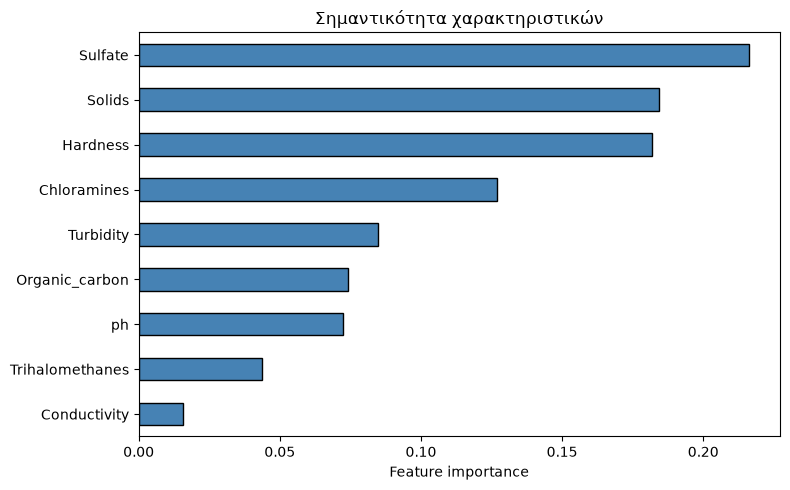

,Importance
Sulfate,0.2164
Solids,0.1845
Hardness,0.1819
Chloramines,0.1268
Turbidity,0.0848
Organic_carbon,0.0741
ph,0.0722
Trihalomethanes,0.0436
Conductivity,0.0157


In [22]:
importance = pd.Series(tree_best.feature_importances_, index=features).sort_values()

plt.figure(figsize=(8, 5))
importance.plot(kind='barh', color='steelblue', edgecolor='black')
plt.xlabel('Feature importance')
plt.title('Σημαντικότητα χαρακτηριστικών')
plt.tight_layout()
plt.show()

importance.sort_values(ascending=False).round(4).to_frame('Importance')

Για να ελέγξω αν 5 χαρακτηριστικά αρκούν, εκπαιδεύω το ίδιο δέντρο μόνο με τα 5 πιο σημαντικά και το συγκρίνω με το δέντρο των 9 χαρακτηριστικών.

In [23]:
top5 = importance.sort_values(ascending=False).index[:5].tolist()
top5_idx = [features.index(f) for f in top5]
print('Top 5 χαρακτηριστικά:', top5)

tree_top5 = DecisionTreeClassifier(random_state=seed, **params_best)
cv_top5 = cross_val_score(tree_top5, x_train[:, top5_idx], y_train, cv=5).mean()
tree_top5.fit(x_train[:, top5_idx], y_train)

cv_all = cross_val_score(DecisionTreeClassifier(random_state=seed, **params_best), x_train, y_train, cv=5).mean()

pd.DataFrame({
    'CV Accuracy': [cv_all, cv_top5],
    'Test Accuracy': [tree_best.score(x_test, y_test), tree_top5.score(x_test[:, top5_idx], y_test)],
}, index=['Και τα 9 χαρακτηριστικά', 'Μόνο τα top 5']).round(4)

Top 5 χαρακτηριστικά: ['Sulfate', 'Solids', 'Hardness', 'Chloramines', 'Turbidity']


,CV Accuracy,Test Accuracy
Και τα 9 χαρακτηριστικά,0.6229,0.6280
Μόνο τα top 5,0.6130,0.5732



Ο συνδυασμός με το μεγαλύτερο test accuracy από όλους τους 96 είναι ο ίδιος με του ερωτήματος 8, γιατί ο καλύτερος συνδυασμός έχει ήδη max_depth = 5. Άρα πρόκειται για το ίδιο δέντρο.

**Ερώτηση: Αν η συσκευή υποστηρίζει μέχρι 5 αναλύσεις, ποια χαρακτηριστικά να εξάγει;**

**Απάντηση:** Τα 5 πιο σημαντικά χαρακτηριστικά του δέντρου είναι τα **Sulfate** (0,216), **Solids** (0,185), **Hardness** (0,182), **Chloramines** (0,127) και **Turbidity** (0,085), που μαζί έχουν περίπου 80% της συνολικής σημαντικότητας. Τα pH, Organic_carbon, Trihalomethanes και Conductivity έχουν από 0,074 και κάτω, με τη Conductivity σχεδόν αμελητέα (0,016). Αξίζει να σημειωθεί ότι το pH, στο οποίο δίνει έμφαση ο ΠΟΥ, δεν μπαίνει στα 5 πρώτα, κάτι που συμφωνεί με το ερώτημα 2.

Για να ελέγξω την επιλογή, εκπαίδευσα το ίδιο δέντρο μόνο με αυτά τα 5. Η απόδοση χειροτερεύει: το cross-validation πέφτει από 62,3% σε 61,3% και το test accuracy από 62,8% σε 57,3%. Άρα η συσκευή θα έπρεπε να μετρά αυτά τα 5, αλλά να είναι σαφές ότι χάνει ακρίβεια σε σχέση με τις 9 αναλύσεις. Η σημαντικότητα ενός δέντρου με τόσο χαμηλή απόδοση πρέπει να διαβάζεται με προσοχή, γιατί οι τιμές της μπορεί να αλλάξουν με άλλο διαχωρισμό των δεδομένων. Επίσης, το 24% των τιμών των Sulfate ήταν ελλιπείς και τις συμπλήρωσα με τη μέση τιμή, κάτι που μπορεί να επηρεάζει τη σημαντικότητά τους.


# 11. Ποια μετρική είναι κατάλληλη;

Αξιολογώ το δέντρο του ερωτήματος 8 με confusion matrix και με μετρικές για κάθε κλάση.

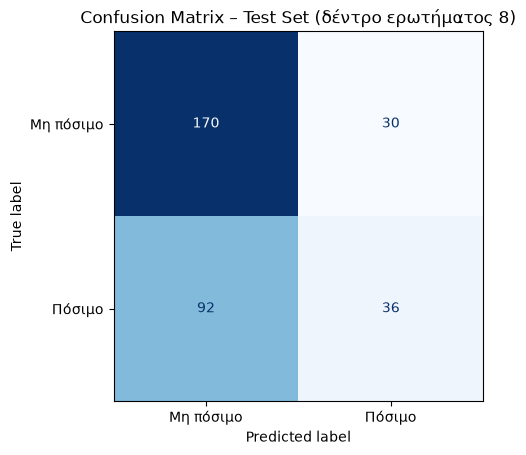

True Negatives (μη πόσιμο, σωστά): 170 | False Positives (μη πόσιμο που προβλέφθηκε πόσιμο): 30
False Negatives (πόσιμο που προβλέφθηκε μη πόσιμο): 92 | True Positives (πόσιμο, σωστά): 36


In [24]:
pred5 = tree5.predict(x_test)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred5,
    display_labels=['Μη πόσιμο', 'Πόσιμο'],
    cmap='Blues',
    colorbar=False,
)
plt.title('Confusion Matrix – Test Set (δέντρο ερωτήματος 8)')
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, pred5).ravel()
print('True Negatives (μη πόσιμο, σωστά):', tn, '| False Positives (μη πόσιμο που προβλέφθηκε πόσιμο):', fp)
print('False Negatives (πόσιμο που προβλέφθηκε μη πόσιμο):', fn, '| True Positives (πόσιμο, σωστά):', tp)

In [25]:
print(classification_report(y_test, pred5, target_names=['Μη πόσιμο', 'Πόσιμο'], zero_division=0))

pd.DataFrame({
    'Τιμή': {
        'Accuracy': accuracy_score(y_test, pred5),
        'Precision πόσιμου (εμπιστοσύνη στο «πόσιμο»)': precision_score(y_test, pred5, zero_division=0),
        'Recall πόσιμου': recall_score(y_test, pred5),
        'Recall μη πόσιμου (specificity)': recall_score(y_test, pred5, pos_label=0),
        'F0.5 πόσιμου (δίνει διπλό βάρος στο precision)': fbeta_score(y_test, pred5, beta=0.5, zero_division=0),
    }
}).round(4)

              precision    recall  f1-score   support

   Μη πόσιμο       0.65      0.85      0.74       200
      Πόσιμο       0.55      0.28      0.37       128

    accuracy                           0.63       328
   macro avg       0.60      0.57      0.55       328
weighted avg       0.61      0.63      0.59       328



,Τιμή
Accuracy,0.6280
Precision πόσιμου (εμπιστοσύνη στο «πόσιμο»),0.5455
Recall πόσιμου,0.2812
Recall μη πόσιμου (specificity),0.8500
F0.5 πόσιμου (δίνει διπλό βάρος στο precision),0.4592



**Ερώτηση: Τι είναι πιο σημαντικό: να προβλέπει καλά το πόσιμο ή το μη πόσιμο νερό;**

**Απάντηση:** Για μια συσκευή ελέγχου πόσιμου νερού το χειρότερο λάθος είναι να πει «πόσιμο» για νερό που δεν είναι, γιατί κάποιος θα το πιει και μπορεί να αρρωστήσει. Το αντίθετο λάθος (να πει «μη πόσιμο» για καλό νερό) κοστίζει μόνο μια επανάληψη του ελέγχου ή περιττή επεξεργασία του νερού. Άρα είναι πιο σημαντικό να προβλέπει καλά το **μη πόσιμο** νερό, ακόμη και αν χάνει ακρίβεια στο πόσιμο.

**Μετρική:** Το accuracy δεν είναι κατάλληλο, γιατί μετρά τα δύο λάθη το ίδιο και γιατί το dataset είναι ανισοβαρές (61% / 39%). Χρησιμοποιώ:
- το **precision του πόσιμου**: από τα δείγματα που η συσκευή χαρακτηρίζει πόσιμα, πόσα είναι πραγματικά πόσιμα,
- το **recall του μη πόσιμου** (specificity): πόσα από τα μη πόσιμα δείγματα εντόπισε,
- το **F0.5 του πόσιμου**, που συνδυάζει precision και recall και δίνει διπλάσιο βάρος στο precision.

**Αξιολόγηση του δέντρου του ερωτήματος 8:** Εντοπίζει σωστά το 85% των μη πόσιμων δειγμάτων (170 από 200). Όμως από τις 66 φορές που είπε «πόσιμο», οι 30 ήταν λάθος, δηλαδή το precision του πόσιμου είναι μόλις 54,5%. Με άλλα λόγια, σχεδόν στο μισό του νερού που θα χαρακτήριζε πόσιμο δεν θα ήταν ασφαλές. Το recall του πόσιμου είναι μόνο 28% (36 από 128), και το F0.5 είναι 0,46. Το δέντρο λοιπόν δεν είναι αρκετά αξιόπιστο για πραγματική χρήση.


# Συμπέρασμα


Το καλύτερο δέντρο (entropy, max_depth = 5, max_features = sqrt) έχει test accuracy 62,8%, ενώ το δέντρο με τις προεπιλεγμένες παραμέτρους 56,4% (με 100% στο train) και ένα μοντέλο που λέει πάντα «μη πόσιμο» 61%. Δηλαδή τα δέντρα αυτού του dataset ξεπερνούν ελάχιστα το απλό όριο αναφοράς. Τα οριακά αποτελέσματα και οι ισοβαθμίες δείχνουν ότι η επιλογή υπερπαραμέτρων με βάση το test set δεν είναι αξιόπιστη. Τα δεδομένα δεν διαχωρίζονται με τα όρια του ΠΟΥ και τα πιο σημαντικά χαρακτηριστικά είναι τα Sulfate, Solids, Hardness, Chloramines και Turbidity. Με 5 αναλύσεις η απόδοση πέφτει ακόμη (57,3%). Επειδή το κρίσιμο λάθος είναι να χαρακτηριστεί πόσιμο ένα επικίνδυνο νερό, και το precision του πόσιμου είναι μόλις 54,5%, το μοντέλο δεν θα μπορούσε να χρησιμοποιηθεί ως ασφαλής έλεγχος πόσιμου νερού.
